<a href="https://colab.research.google.com/github/noorahmedbhatti007-byte/US-Airline-Flight-Delays-PySpark/blob/main/BAN_5600_Team_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Uncomment on Google Colab or any machine without PySpark:
!pip install -q pyspark

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F, types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.functions import vector_to_array

try:
    display  # available in Jupyter / Colab
except NameError:
    display = print

##Environment setup

In [ ]:
os.environ["FLIGHTS_DATA_DIR"] = "/content"

DATA_DIR = os.getenv("FLIGHTS_DATA_DIR", "data")
OUTPUT_DIR = os.getenv("FLIGHTS_OUTPUT_DIR", "outputs")
FIG_DIR, TABLE_DIR = os.path.join(OUTPUT_DIR, "figures"), os.path.join(OUTPUT_DIR, "tables")

DELAY_THRESHOLD = 15
SEED = 42
MODEL_SAMPLE_FRACTION = float(os.getenv("MODEL_SAMPLE_FRACTION", "0.20"))
TUNING_SAMPLE_FRACTION = float(os.getenv("TUNING_SAMPLE_FRACTION", "0.30"))
MIN_FLIGHTS_AIRPORT = int(os.getenv("MIN_FLIGHTS_AIRPORT", "5000"))
MIN_FLIGHTS_ROUTE = int(os.getenv("MIN_FLIGHTS_ROUTE", "1000"))
TE_SMOOTHING = 50
DRIVER_MEMORY = os.getenv("SPARK_DRIVER_MEMORY", "8g")

for d in (FIG_DIR, TABLE_DIR):
    os.makedirs(d, exist_ok=True)

In [ ]:
spark = (
    SparkSession.builder
    .appName("US-Flight-Delays-2015")
    .master("local[*]")                       # remove this line on Databricks / a real cluster
    .config("spark.driver.memory", DRIVER_MEMORY)
    .config("spark.sql.shuffle.partitions", "64")
    .config("spark.sql.adaptive.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| cores:", spark.sparkContext.defaultParallelism)

Spark 4.0.4 | cores: 2


Chart Styles


In [ ]:
ACCENT = "#2a78d6"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlecolor": INK, "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
RATE_LABEL = f"Share of flights arriving ≥{DELAY_THRESHOLD} min late"


def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, f"{name}.png"))
    plt.show()
    plt.close(fig)


def save_table(pdf, name):
    pdf.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"), index=False)
    return pdf


def _ref_line(ax, ref, vertical):
    if ref is None:
        return
    if vertical:
        ax.axvline(ref, color=MUTED, ls="--", lw=1)
        ax.annotate(f"overall {ref:.1%}", xy=(ref, 1), xycoords=("data", "axes fraction"),
                    xytext=(3, 2), textcoords="offset points", color=MUTED, fontsize=8, va="bottom")
    else:
        ax.axhline(ref, color=MUTED, ls="--", lw=1)
        ax.annotate(f"overall {ref:.1%}", xy=(1, ref), xycoords=("axes fraction", "data"),
                    xytext=(-2, 3), textcoords="offset points", color=MUTED, fontsize=8, ha="right")


def hbar(pdf, label_col, value_col, title, name, ref=None, xlabel=RATE_LABEL, pct=True):
    pdf = pdf.sort_values(value_col)
    fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(pdf) + 1.3))
    ax.barh(pdf[label_col].astype(str), pdf[value_col], color=ACCENT, height=0.68)
    for y, v in enumerate(pdf[value_col]):
        ax.text(v, y, f" {v:.1%}" if pct else f" {v:,.1f}", va="center", fontsize=8, color=INK2)
    _ref_line(ax, ref, vertical=True)
    if pct:
        ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.margins(x=0.12)
    save_fig(fig, name)


def vbar(pdf, label_col, value_col, title, name, ref=None, xlabel=None, ylabel=RATE_LABEL):
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.bar(pdf[label_col].astype(str), pdf[value_col], color=ACCENT, width=0.68)
    for x, v in enumerate(pdf[value_col]):
        ax.text(x, v, f"{v:.1%}", ha="center", va="bottom", fontsize=8, color=INK2)
    _ref_line(ax, ref, vertical=False)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel or "")
    ax.set_ylabel(ylabel)
    save_fig(fig, name)


def line(pdf, x_col, value_col, title, name, ref=None, xlabel=None, ylabel=RATE_LABEL, xticklabels=None):
    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.plot(pdf[x_col], pdf[value_col], color=ACCENT, lw=2, marker="o", ms=5)
    _ref_line(ax, ref, vertical=False)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    if xticklabels is not None:
        ax.set_xticks(list(pdf[x_col]))
        ax.set_xticklabels(xticklabels)
    ax.set_title(title)
    ax.set_xlabel(xlabel or "")
    ax.set_ylabel(ylabel)
    save_fig(fig, name)

Selecting Variables

In [ ]:
INT, DBL, STR = T.IntegerType(), T.DoubleType(), T.StringType()
flights_schema = T.StructType([T.StructField(n, t, True) for n, t in [
    ("YEAR", INT), ("MONTH", INT), ("DAY", INT), ("DAY_OF_WEEK", INT), ("AIRLINE", STR),
    ("FLIGHT_NUMBER", INT), ("TAIL_NUMBER", STR), ("ORIGIN_AIRPORT", STR), ("DESTINATION_AIRPORT", STR),
    ("SCHEDULED_DEPARTURE", INT), ("DEPARTURE_TIME", INT), ("DEPARTURE_DELAY", DBL), ("TAXI_OUT", DBL),
    ("WHEELS_OFF", INT), ("SCHEDULED_TIME", DBL), ("ELAPSED_TIME", DBL), ("AIR_TIME", DBL), ("DISTANCE", DBL),
    ("WHEELS_ON", INT), ("TAXI_IN", DBL), ("SCHEDULED_ARRIVAL", INT), ("ARRIVAL_TIME", INT),
    ("ARRIVAL_DELAY", DBL), ("DIVERTED", INT), ("CANCELLED", INT), ("CANCELLATION_REASON", STR),
    ("AIR_SYSTEM_DELAY", DBL), ("SECURITY_DELAY", DBL), ("AIRLINE_DELAY", DBL),
    ("LATE_AIRCRAFT_DELAY", DBL), ("WEATHER_DELAY", DBL),
]])

flights_raw = spark.read.csv(os.path.join(DATA_DIR, "flights.csv"), header=True, schema=flights_schema)
airlines = spark.read.csv(os.path.join(DATA_DIR, "airlines.csv"), header=True, inferSchema=True)
airports = spark.read.csv(os.path.join(DATA_DIR, "airports.csv"), header=True, inferSchema=True)

n_raw = flights_raw.count()
print(f"flights: {n_raw:,} rows × {len(flights_raw.columns)} columns")
print(f"airlines: {airlines.count()} rows | airports: {airports.count()} rows")
flights_raw.printSchema()

flights: 5,819,079 rows × 31 columns
airlines: 14 rows | airports: 322 rows
root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: integer (nullable = true)
 |-- DEPARTURE_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: integer (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- WHEELS_ON: integer (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- SCHEDULED_ARRIVAL: integer (nullable = true)
 |-- ARRI

##Handling Missing Values

In [ ]:
INT, DBL, STR = T.IntegerType(), T.DoubleType(), T.StringType()
flights_schema = T.StructType([T.StructField(n, t, True) for n, t in [
    ("YEAR", INT), ("MONTH", INT), ("DAY", INT), ("DAY_OF_WEEK", INT), ("AIRLINE", STR),
    ("FLIGHT_NUMBER", INT), ("TAIL_NUMBER", STR), ("ORIGIN_AIRPORT", STR), ("DESTINATION_AIRPORT", STR),
    ("SCHEDULED_DEPARTURE", INT), ("DEPARTURE_TIME", INT), ("DEPARTURE_DELAY", DBL), ("TAXI_OUT", DBL),
    ("WHEELS_OFF", INT), ("SCHEDULED_TIME", DBL), ("ELAPSED_TIME", DBL), ("AIR_TIME", DBL), ("DISTANCE", DBL),
    ("WHEELS_ON", INT), ("TAXI_IN", DBL), ("SCHEDULED_ARRIVAL", INT), ("ARRIVAL_TIME", INT),
    ("ARRIVAL_DELAY", DBL), ("DIVERTED", INT), ("CANCELLED", INT), ("CANCELLATION_REASON", STR),
    ("AIR_SYSTEM_DELAY", DBL), ("SECURITY_DELAY", DBL), ("AIRLINE_DELAY", DBL),
    ("LATE_AIRCRAFT_DELAY", DBL), ("WEATHER_DELAY", DBL),
]])

flights_raw = spark.read.csv(os.path.join(DATA_DIR, "flights.csv"), header=True, schema=flights_schema)
airlines = spark.read.csv(os.path.join(DATA_DIR, "airlines.csv"), header=True, inferSchema=True)
airports = spark.read.csv(os.path.join(DATA_DIR, "airports.csv"), header=True, inferSchema=True)

n_raw = flights_raw.count()
print(f"flights: {n_raw:,} rows × {len(flights_raw.columns)} columns")
print(f"airlines: {airlines.count()} rows | airports: {airports.count()} rows")
flights_raw.printSchema()

flights: 5,819,079 rows × 31 columns
airlines: 14 rows | airports: 322 rows
root
 |-- YEAR: integer (nullable = true)
 |-- MONTH: integer (nullable = true)
 |-- DAY: integer (nullable = true)
 |-- DAY_OF_WEEK: integer (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- FLIGHT_NUMBER: integer (nullable = true)
 |-- TAIL_NUMBER: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: integer (nullable = true)
 |-- DEPARTURE_TIME: integer (nullable = true)
 |-- DEPARTURE_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: integer (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- WHEELS_ON: integer (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- SCHEDULED_ARRIVAL: integer (nullable = true)
 |-- ARRI

In [ ]:
missing = (
    flights_raw.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in flights_raw.columns])
    .toPandas().T.reset_index()
)
missing.columns = ["column", "missing"]
missing["missing_pct"] = (missing["missing"] / n_raw * 100).round(2)
display(save_table(missing.sort_values("missing", ascending=False), "02_missing_values"))

,column,missing,missing_pct
25,CANCELLATION_REASON,5729195,98.46
29,LATE_AIRCRAFT_DELAY,4755640,81.72
30,WEATHER_DELAY,4755640,81.72
28,AIRLINE_DELAY,4755640,81.72
26,AIR_SYSTEM_DELAY,4755640,81.72
27,SECURITY_DELAY,4755640,81.72
15,ELAPSED_TIME,105071,1.81
16,AIR_TIME,105071,1.81
22,ARRIVAL_DELAY,105071,1.81
18,WHEELS_ON,92513,1.59


- The five delay-cause columns are empty for 81.7% of rows because BTS only records cause minutes for flights that arrive **15+ minutes late** (confirmed in the data-quality check below).
- `CANCELLATION_REASON` is empty for 98.5% of rows because only cancelled flights have a reason.
- Actual-time columns (`DEPARTURE_TIME`, `ARRIVAL_DELAY`, etc.) are missing for 1.5–1.8% of rows, which are the cancelled and diverted flights that never completed a normal arrival.

Because `ARRIVAL_DELAY` is missing exactly for flights without a normal outcome, the target `DELAYED` is only defined for completed flights. Cancelled and diverted flights are described separately rather than forced into the on-time/delayed label.

###Flight outcomes, cancellations and descriptive statistics

Here we examine flight cancellations and diversions, identifies the most common cancellation reasons, and summarizes key flight characteristics, including departure and arrival delays, taxi times, scheduled flight duration, and distance.

In [ ]:
CANCEL_REASONS = {"A": "Airline/Carrier", "B": "Weather", "C": "National Air System", "D": "Security"}
cancel_map = F.create_map(*[F.lit(x) for kv in CANCEL_REASONS.items() for x in kv])

outcomes = (flights_raw.groupBy("CANCELLED", "DIVERTED").count()
            .withColumn("share", F.col("count") / n_raw).orderBy("CANCELLED", "DIVERTED").toPandas())
display(outcomes)

(flights_raw.filter("CANCELLED = 1")
 .groupBy(cancel_map[F.col("CANCELLATION_REASON")].alias("cancellation_reason")).count()
 .orderBy(F.desc("count")).show())

DELAY_VARS = ["DEPARTURE_DELAY", "ARRIVAL_DELAY", "TAXI_OUT", "TAXI_IN", "SCHEDULED_TIME", "DISTANCE"]
display(flights_raw.select(DELAY_VARS).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max").toPandas())

,CANCELLED,DIVERTED,count,share
0,0,0,5714008,0.981944
1,0,1,15187,0.002610
2,1,0,89884,0.015446


+-------------------+-----+
|cancellation_reason|count|
+-------------------+-----+
|            Weather|48851|
|    Airline/Carrier|25262|
|National Air System|15749|
|           Security|   22|
+-------------------+-----+



,summary,DEPARTURE_DELAY,ARRIVAL_DELAY,TAXI_OUT,TAXI_IN,SCHEDULED_TIME,DISTANCE
0,count,5732926,5714008,5730032,5726566,5819073,5819079
1,mean,9.370158275198389,4.407057357987598,16.07166225249702,7.4349708010001105,141.6858915500802,822.3564947305235
2,stddev,37.08094249678714,39.27129709388608,8.895574065449845,5.638547687322099,75.21058230600121,607.7842873170487
3,min,-82.0,-87.0,1.0,1.0,18.0,21.0
4,25%,-5.0,-13.0,11.0,4.0,85.0,373.0
5,50%,-2.0,-5.0,14.0,6.0,123.0,647.0
6,75%,7.0,8.0,19.0,9.0,173.0,1065.0
7,max,1988.0,1971.0,225.0,248.0,718.0,4983.0


**Flight outcomes and cancellations.** Of 5,819,079 scheduled flights:
- **98.2%** were completed,
- **1.54%** (89,884) were cancelled,
- **0.26%** (15,187) were diverted.

**Weather drives cancellations:** it accounts for **54%** of cancellations, compared with 28% for the airline/carrier, 18% for the National Air System and almost none for security (22 flights). This matters for interpreting the delay causes later. Severe weather tends to show up as **cancellations** rather than as delayed flights.

The descriptive statistics confirm the skew discussed above: departure delays average 9.4 minutes but the median is −2 (early). Taxi-out (median 14 min) is roughly twice taxi-in (median 6 min), which points to departure-side congestion at airports

###Data quality check

Here we categorise Delay-cause columns that is populated only when ARRIVAL_DELAY ≥ 15 and duplicates identified by date + airline + flight number + origin + scheduled departure.

In [ ]:
iata_ok = F.col("ORIGIN_AIRPORT").rlike("^[A-Z]{3}$") & F.col("DESTINATION_AIRPORT").rlike("^[A-Z]{3}$")
display(flights_raw.groupBy("MONTH").agg(
    F.count("*").alias("flights"),
    F.sum((~iata_ok).cast("int")).alias("non_IATA_airport_codes")).orderBy("MONTH").toPandas())

CAUSE_COLS = {
    "AIRLINE_DELAY": "Air carrier",
    "LATE_AIRCRAFT_DELAY": "Late-arriving aircraft",
    "AIR_SYSTEM_DELAY": "National Aviation System",
    "WEATHER_DELAY": "Weather",
    "SECURITY_DELAY": "Security",
}
display(flights_raw.filter("ARRIVAL_DELAY IS NOT NULL").groupBy(
    (F.col("ARRIVAL_DELAY") >= DELAY_THRESHOLD).alias("arrival_delay_ge_15")).agg(
    F.count("*").alias("flights"),
    F.sum(F.col("AIRLINE_DELAY").isNotNull().cast("int")).alias("rows_with_cause_minutes")).toPandas())

KEY = ["YEAR", "MONTH", "DAY", "AIRLINE", "FLIGHT_NUMBER", "ORIGIN_AIRPORT", "SCHEDULED_DEPARTURE"]
n_unique = flights_raw.select(KEY).distinct().count()
print(f"Duplicate flight keys: {n_raw - n_unique:,}")

,MONTH,flights,non_IATA_airport_codes
0,1,469968,0
1,2,429191,0
2,3,504312,0
3,4,485151,0
4,5,496993,0
5,6,503897,0
6,7,520718,0
7,8,510536,0
8,9,464946,0
9,10,486165,486165


,arrival_delay_ge_15,flights,rows_with_cause_minutes
0,False,4650569,0
1,True,1063439,1063439


Duplicate flight keys: 1


1. **October airport codes are not IATA codes.** All 486,165 October flights use numeric airport IDs instead of 3-letter IATA codes, so they cannot be joined to `airports.csv`. We flag these rows with `IATA_CODES_VALID`; they are kept for airline and time analyses but excluded from airport-level analysis and from modelling.
2. **Delay-cause columns are populated exactly when `ARRIVAL_DELAY ≥ 15`.** All 1,063,439 delayed flights have cause minutes, and none of the 4,650,569 on-time flights do. This confirms both that our 15-minute target matches the BTS definition and that cause minutes are **post-outcome information**. They are used only for descriptive analysis and never as predictors.
3. **Duplicates are negligible.** One duplicated flight key was found and removed.

###Data Preparation


Convert HHMM integers (e.g. 5 = 00:05, 2400 = midnight) to minutes after midnight, hour of day and a departure period.
Build the flight date, weekday name, distance band, route, flight status and the target DELAYED.
Flag records whose airport codes are valid IATA codes.

In [ ]:
def hhmm_to_minutes(c):
    return ((F.floor(F.col(c) / 100) * 60 + F.col(c) % 100) % 1440).cast("int")


DOW_NAMES = {1: "Mon", 2: "Tue", 3: "Wed", 4: "Thu", 5: "Fri", 6: "Sat", 7: "Sun"}
dow_map = F.create_map(*[F.lit(x) for kv in DOW_NAMES.items() for x in kv])

flights = (
    flights_raw.dropDuplicates(KEY)
    .withColumn("FLIGHT_DATE", F.make_date("YEAR", "MONTH", "DAY"))
    .withColumn("DAY_NAME", dow_map[F.col("DAY_OF_WEEK")])
    .withColumn("IS_WEEKEND", F.col("DAY_OF_WEEK").isin(6, 7).cast("int"))
    .withColumn("SCHED_DEP_MIN", hhmm_to_minutes("SCHEDULED_DEPARTURE"))
    .withColumn("SCHED_ARR_MIN", hhmm_to_minutes("SCHEDULED_ARRIVAL"))
    .withColumn("DEP_HOUR", (F.col("SCHED_DEP_MIN") / 60).cast("int"))
    .withColumn("ARR_HOUR", (F.col("SCHED_ARR_MIN") / 60).cast("int"))
    .withColumn("DEP_PERIOD",
                F.when(F.col("DEP_HOUR") < 6, "1 Night (00–05)")
                 .when(F.col("DEP_HOUR") < 12, "2 Morning (06–11)")
                 .when(F.col("DEP_HOUR") < 18, "3 Afternoon (12–17)")
                 .otherwise("4 Evening (18–23)"))
    .withColumn("DISTANCE_BAND",
                F.when(F.col("DISTANCE") < 250, "1 <250 mi")
                 .when(F.col("DISTANCE") < 500, "2 250–499")
                 .when(F.col("DISTANCE") < 1000, "3 500–999")
                 .when(F.col("DISTANCE") < 1500, "4 1000–1499")
                 .when(F.col("DISTANCE") < 2000, "5 1500–1999")
                 .otherwise("6 2000+ mi"))
    .withColumn("ROUTE", F.concat_ws("-", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT"))
    .withColumn("IATA_CODES_VALID", iata_ok)
    .withColumn("FLIGHT_STATUS",
                F.when(F.col("CANCELLED") == 1, "Cancelled")
                 .when(F.col("DIVERTED") == 1, "Diverted").otherwise("Completed"))
    .withColumn("CANCELLATION_REASON_DESC", cancel_map[F.col("CANCELLATION_REASON")])
    # Target: defined only for completed flights with a recorded arrival delay
    .withColumn("DELAYED",
                F.when((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0) & F.col("ARRIVAL_DELAY").isNotNull(),
                       (F.col("ARRIVAL_DELAY") >= DELAY_THRESHOLD).cast("int")))
)

Remove duplicate flight keys (if any).
Convert HHMM integers (e.g. 5 = 00:05, 2400 = midnight) to minutes after midnight, hour of day and a departure period.
Build the flight date, weekday name, distance band, route, flight status and the target DELAYED.
Flag records whose airport codes are valid IATA codes.

In [ ]:
airlines_ref = airlines.select(F.col("IATA_CODE").alias("AIRLINE"), F.col("AIRLINE").alias("AIRLINE_NAME"))


def airport_ref(prefix, key):
    return airports.select(
        F.col("IATA_CODE").alias(key), F.col("AIRPORT").alias(f"{prefix}_NAME"),
        F.col("CITY").alias(f"{prefix}_CITY"), F.col("STATE").alias(f"{prefix}_STATE"),
        F.col("LATITUDE").alias(f"{prefix}_LAT"), F.col("LONGITUDE").alias(f"{prefix}_LON"))


flights = (
    flights
    .join(F.broadcast(airlines_ref), "AIRLINE", "left")
    .join(F.broadcast(airport_ref("ORIGIN", "ORIGIN_AIRPORT")), "ORIGIN_AIRPORT", "left")
    .join(F.broadcast(airport_ref("DEST", "DESTINATION_AIRPORT")), "DESTINATION_AIRPORT", "left")
)

In [ ]:
HOLIDAYS = ["2015-01-01", "2015-01-19", "2015-02-16", "2015-05-25", "2015-07-04",
            "2015-09-07", "2015-11-26", "2015-12-25", "2016-01-01"]

w_tail_day = Window.partitionBy("TAIL_NUMBER", "FLIGHT_DATE")
w_tail_seq = w_tail_day.orderBy("SCHED_DEP_MIN")
has_tail = F.col("TAIL_NUMBER").isNotNull()

flights = (
    flights
    .withColumn("DAYS_TO_HOLIDAY",
                F.array_min(F.array(*[F.abs(F.datediff("FLIGHT_DATE", F.lit(h).cast("date"))) for h in HOLIDAYS])))
    .withColumn("ORIGIN_HOUR_DEPS", F.count("*").over(Window.partitionBy("ORIGIN_AIRPORT", "FLIGHT_DATE", "DEP_HOUR")))
    .withColumn("DEST_HOUR_ARRS", F.count("*").over(Window.partitionBy("DESTINATION_AIRPORT", "FLIGHT_DATE", "ARR_HOUR")))
    .withColumn("ORIGIN_DAY_DEPS", F.count("*").over(Window.partitionBy("ORIGIN_AIRPORT", "FLIGHT_DATE")))
    .withColumn("TAIL_LEG_NUM", F.when(has_tail, F.row_number().over(w_tail_seq)).otherwise(1))
    .withColumn("TAIL_DAILY_LEGS", F.when(has_tail, F.count("*").over(w_tail_day)).otherwise(1))
    .withColumn("PREV_SCHED_ARR_MIN", F.when(has_tail, F.lag("SCHED_ARR_MIN").over(w_tail_seq)))
    # Scheduled times are local; the previous leg lands at this flight's origin, so the gap is in the same time zone
    .withColumn("TURNAROUND_MIN",
                F.least(F.coalesce((F.col("SCHED_DEP_MIN") - F.col("PREV_SCHED_ARR_MIN") + 1440) % 1440,
                                   F.lit(600)), F.lit(600)))
    .withColumn("IS_FIRST_LEG", (F.col("TAIL_LEG_NUM") == 1).cast("int"))
    .withColumn("AIRLINE_ORIGIN", F.concat_ws("_", "AIRLINE", "ORIGIN_AIRPORT"))
    .withColumn("ORIGIN_DEP_HOUR", F.concat_ws("_", "ORIGIN_AIRPORT", F.col("DEP_HOUR").cast("string")))
    .drop("PREV_SCHED_ARR_MIN")
)

# Exploratory data Analysis

In [ ]:
completed = flights.filter(F.col("DELAYED").isNotNull())
completed_iata = completed.filter("IATA_CODES_VALID")


def delay_profile(df, group_cols, min_flights=0):
    return (df.groupBy(*group_cols).agg(
                F.count("*").alias("flights"),
                F.avg("DELAYED").alias("delay_rate"),
                F.avg("ARRIVAL_DELAY").alias("mean_arrival_delay"),
                F.expr("percentile_approx(ARRIVAL_DELAY, 0.5)").alias("median_arrival_delay"))
            .filter(F.col("flights") >= min_flights))


kpi = flights.agg(
    F.count("*").alias("scheduled_flights"),
    F.avg("CANCELLED").alias("cancellation_rate"),
    F.avg("DIVERTED").alias("diversion_rate"),
    F.avg("DELAYED").alias("arrival_delay_rate"),
    F.avg("ARRIVAL_DELAY").alias("mean_arrival_delay_min"),
    F.avg("DEPARTURE_DELAY").alias("mean_departure_delay_min"),
).toPandas()
OVERALL_RATE = float(kpi.loc[0, "arrival_delay_rate"])
display(save_table(kpi, "04_overall_kpis"))

,scheduled_flights,cancellation_rate,diversion_rate,arrival_delay_rate,mean_arrival_delay_min,mean_departure_delay_min
0,5819078,0.015446,0.00261,0.186111,4.407057,9.370158


Across all scheduled flights, **18.6%** of completed flights arrived 15 or more minutes late, 1.5% were cancelled and 0.3% diverted. The average arrival delay is only 4.4 minutes because early arrivals offset late ones. This is why we focus on the *share* of significantly delayed flights rather than the average delay throughout the analysis. The 18.6% figure is the reference line (dashed) on every chart that follows.

###Distribution of arrival delay

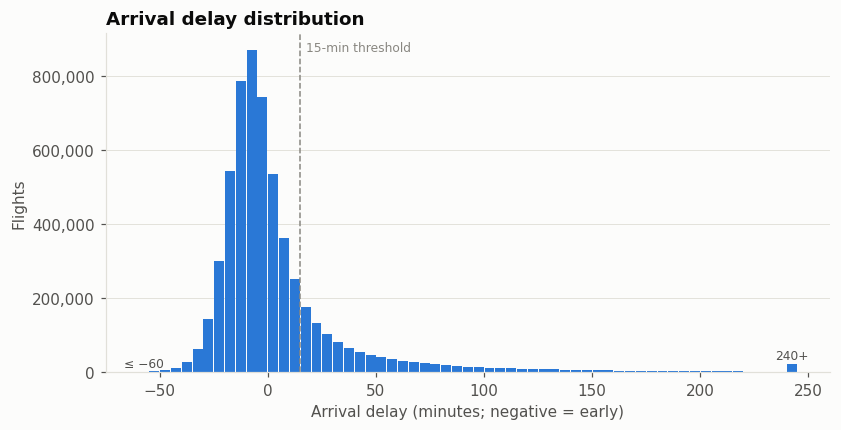

In [ ]:
hist = (completed.select(F.least(F.greatest(F.col("ARRIVAL_DELAY"), F.lit(-60)), F.lit(240)).alias("d"))
        .groupBy((F.floor(F.col("d") / 5) * 5).alias("bin")).count().orderBy("bin").toPandas())
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(hist["bin"] + 2.5, hist["count"], width=4.6, color=ACCENT)
ax.axvline(DELAY_THRESHOLD, color=MUTED, ls="--", lw=1)
ax.annotate(f"{DELAY_THRESHOLD}-min threshold", xy=(DELAY_THRESHOLD, 1), xycoords=("data", "axes fraction"),
            xytext=(4, -12), textcoords="offset points", color=MUTED, fontsize=8)
for b, txt in [(hist["bin"].min(), "≤ −60"), (hist["bin"].max(), "240+")]:
    ax.annotate(txt, xy=(b + 2.5, hist.loc[hist["bin"] == b, "count"].iloc[0]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.set_title("Arrival delay distribution")
ax.set_xlabel("Arrival delay (minutes; negative = early)")
ax.set_ylabel("Flights")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="x", visible=False)
save_fig(fig, "04_1_arrival_delay_distribution")

The median arrival is **5 minutes early** and the mean is only 4.4 minutes late. However, the distribution is strongly right-skewed .

 The dashed line marks the 15-minute threshold used for our target: **18.6%** of completed flights fall to the right of it. So the average flight hides the problem; delay is a minority event, but when it happens it can be large. This also tells us the modelling task is **imbalanced** (roughly 1 delayed flight for every 4 on-time), which shapes how we evaluate models later.

###**Airlines**

,AIRLINE,AIRLINE_NAME,flights,delay_rate,mean_arrival_delay,median_arrival_delay
2,NK,Spirit Air Lines,115193,0.297075,14.471800,0.0
12,F9,Frontier Airlines Inc.,90090,0.261627,12.504706,-1.0
11,B6,JetBlue Airways,262042,0.225823,6.677861,-5.0
8,MQ,American Eagle Airlines Inc.,278791,0.217177,6.457873,-6.0
6,UA,United Air Lines Inc.,507762,0.206242,5.431594,-6.0
3,EV,Atlantic Southeast Airlines,554752,0.196816,6.585379,-4.0
7,VX,Virgin America,61248,0.192300,4.737706,-3.0
13,WN,Southwest Airlines Co.,1242403,0.190458,4.374964,-4.0
9,US,US Airways Inc.,194223,0.188181,3.706209,-4.0
10,OO,Skywest Airlines Inc.,576814,0.186880,5.845652,-4.0


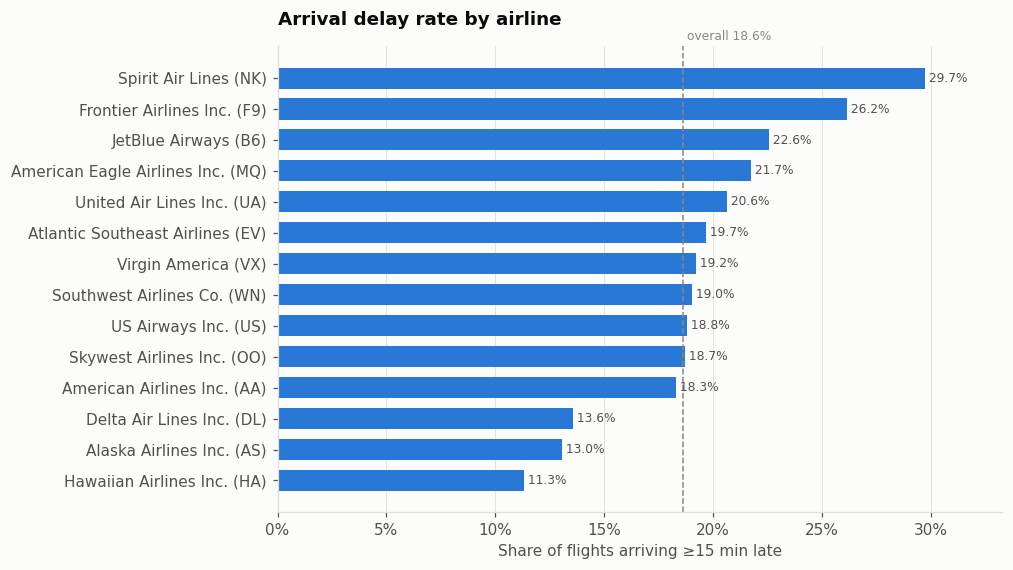

In [ ]:
by_airline = save_table(delay_profile(completed, ["AIRLINE", "AIRLINE_NAME"]).toPandas()
                        .sort_values("delay_rate", ascending=False), "04_2_delay_by_airline")
display(by_airline)
hbar(by_airline.assign(label=by_airline["AIRLINE_NAME"] + " (" + by_airline["AIRLINE"] + ")"),
     "label", "delay_rate", "Arrival delay rate by airline", "04_2_delay_by_airline", ref=OVERALL_RATE)

Against an overall rate of **18.6%**, delay rates range from **11.3% (Hawaiian)** to **29.7% (Spirit)**, a 2.6× difference.
- **Ultra-low-cost carriers are the worst performers:** Spirit (29.7%) and Frontier (26.2%), followed by JetBlue (22.6%).
- **Size is not the explanation:** Delta flew 870k flights, the second most of any airline, and still had one of the lowest rates (13.6%). Alaska (13.0%) and Hawaiian (11.3%) also stand out, both of which operate in less congested or weather-sheltered networks.
- Spirit is the only airline whose *median* flight is not early (0 min), meaning delay is routine rather than occasional for that carrier.

### Time patterns: month, day of week, departure hour and period

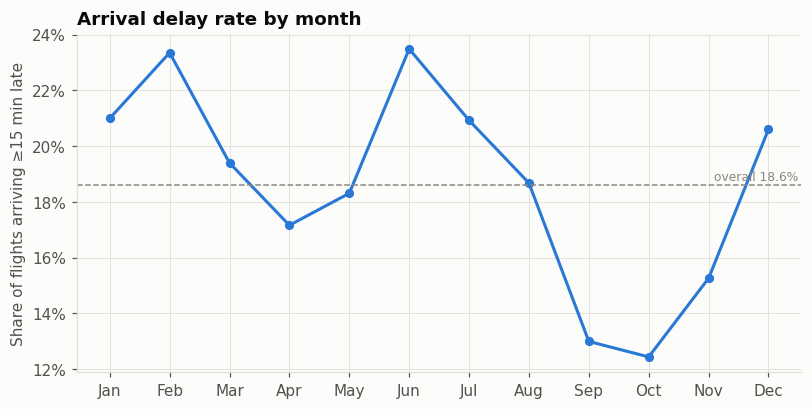

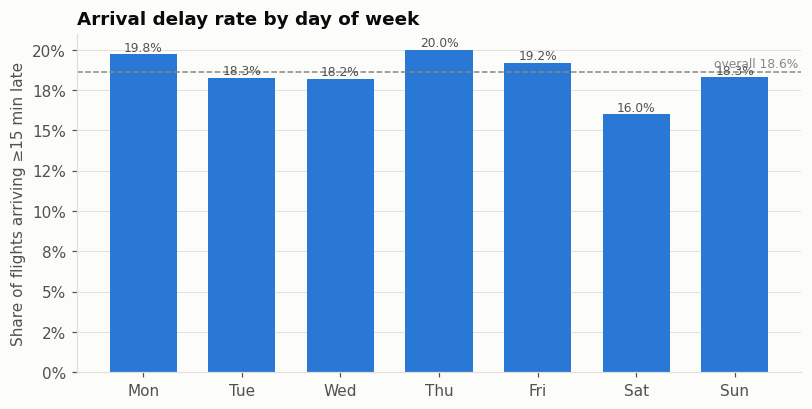

In [ ]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = save_table(delay_profile(completed, ["MONTH"]).orderBy("MONTH").toPandas(), "04_3_delay_by_month")
line(by_month, "MONTH", "delay_rate", "Arrival delay rate by month", "04_3_delay_by_month",
     ref=OVERALL_RATE, xticklabels=[MONTHS[m - 1] for m in by_month["MONTH"]])

by_dow = save_table(delay_profile(completed, ["DAY_OF_WEEK", "DAY_NAME"]).orderBy("DAY_OF_WEEK").toPandas(),
                    "04_3_delay_by_day_of_week")
vbar(by_dow, "DAY_NAME", "delay_rate", "Arrival delay rate by day of week", "04_3_delay_by_day_of_week",
     ref=OVERALL_RATE)

Arrival delay rates varied throughout 2015, peaking in February and June at approximately 23.5%, while October recorded the lowest rate at about 12.5%. These fluctuations suggest seasonal patterns in flight delays, with several months exceeding the overall delay rate of 18.6%.

Arrival delay rates also varied by day of the week, with Thursday recording the highest rate at 20.0%, followed by Monday at 19.8%. Saturday had the lowest delay rate at 16.0%, suggesting that flights were generally more punctual on Saturdays than on other days.

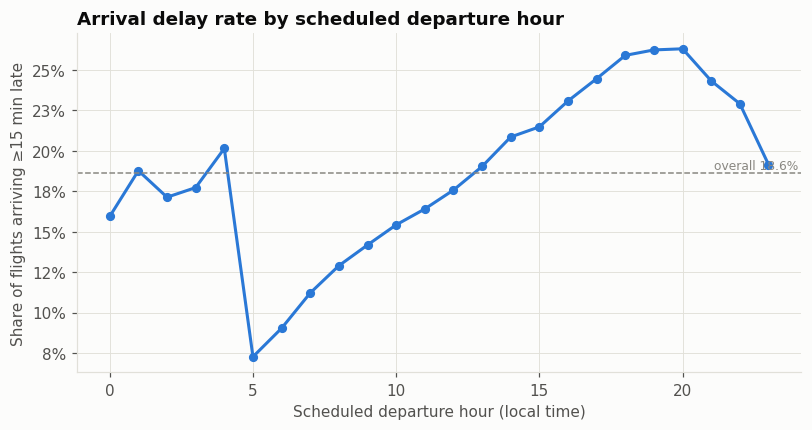

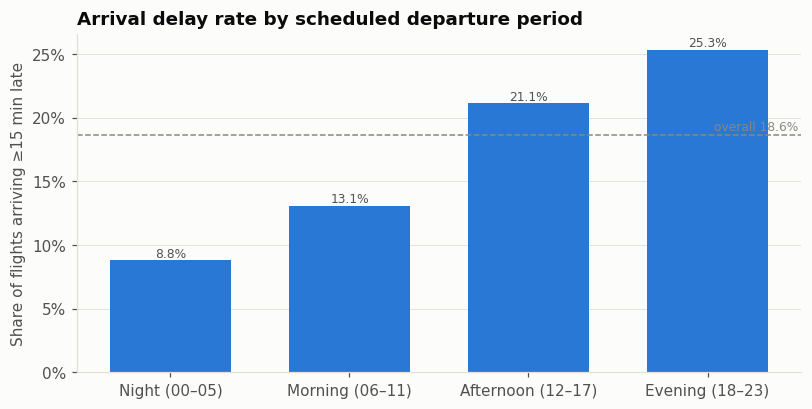

In [ ]:
by_hour = save_table(delay_profile(completed, ["DEP_HOUR"]).orderBy("DEP_HOUR").toPandas(), "04_3_delay_by_dep_hour")
line(by_hour, "DEP_HOUR", "delay_rate", "Arrival delay rate by scheduled departure hour", "04_3_delay_by_dep_hour",
     ref=OVERALL_RATE, xlabel="Scheduled departure hour (local time)")

by_period = save_table(delay_profile(completed, ["DEP_PERIOD"]).orderBy("DEP_PERIOD").toPandas(),
                       "04_3_delay_by_dep_period")
by_period["DEP_PERIOD"] = by_period["DEP_PERIOD"].str[2:]
vbar(by_period, "DEP_PERIOD", "delay_rate", "Arrival delay rate by scheduled departure period",
     "04_3_delay_by_dep_period", ref=OVERALL_RATE)

Arrival delay rates generally increase as the day progresses, with early morning flights recording the lowest rates and evening flights reaching approximately 26%. This suggests that flights scheduled later in the day are more likely to experience delays, potentially due to disruptions accumulating throughout the day.

The chart shows a clear increase in arrival delays across departure periods, from 8.8% at night and 13.1% in the morning to 21.1% in the afternoon and 25.3% in the evening. This indicates that flights scheduled later in the day experience higher delay rates, highlighting departure time as a potentially important predictor of flight delays.

In [ ]:
by_dist = save_table(delay_profile(completed, ["DISTANCE_BAND"]).orderBy("DISTANCE_BAND").toPandas(),
                     "04_4_delay_by_distance")
by_dist["DISTANCE_BAND"] = by_dist["DISTANCE_BAND"].str[2:]
vbar(by_dist, "DISTANCE_BAND", "delay_rate", "Arrival delay rate by flight distance", "04_4_delay_by_distance",
     ref=OVERALL_RATE, xlabel="Distance band (miles)")

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    by_dist["DISTANCE_BAND"],
    by_dist["delay_rate"],
    color=ACCENT
)

ax.axhline(
    OVERALL_RATE,
    color=MUTED,
    linestyle="--",
    label="Overall delay rate"
)

ax.set_ylim(0, 0.25)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.set_title("Arrival delay rate by flight distance")
ax.set_xlabel("Distance band (miles)")
ax.set_ylabel("Flights arriving ≥15 min late")

plt.xticks(rotation=0)
plt.tight_layout()

save_fig(fig, "04_4_delay_by_distance")

Delay rates are almost flat across distance bands, from **17.7%** for flights under 250 miles to a peak of **19.7%** at 1,000–1,499 miles, all within about one percentage point of the overall 18.6%. Delays are mainly generated on the ground (gates, taxiways, congested airspace near hubs, late inbound aircraft) rather than in flight, so trip length has little to do with them. We keep `DISTANCE` and `SCHEDULED_TIME` as features, but we do not expect them to be strong predictors.


###Reported delay categories

,cause,delay_minutes,flights_affected,share_of_minutes,share_of_delayed_flights
1,Late-arriving aircraft,24961931.0,556953.0,0.398423,0.523728
0,Air carrier,20172956.0,570022.0,0.321985,0.536018
2,National Aviation System,14335762.0,564826.0,0.228816,0.531132
3,Weather,3100233.0,64716.0,0.049483,0.060855
4,Security,80985.0,3484.0,0.001293,0.003276


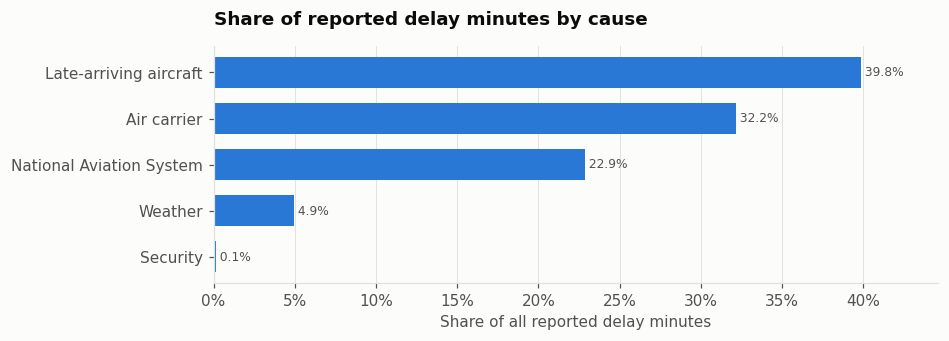

In [ ]:
delayed_flights = completed.filter("DELAYED = 1")
cause_totals = delayed_flights.agg(
    *[F.sum(c).alias(c) for c in CAUSE_COLS],
    *[F.sum((F.col(c) > 0).cast("int")).alias(f"{c}__flights") for c in CAUSE_COLS],
    F.count("*").alias("delayed_flights")).toPandas().iloc[0]

causes = pd.DataFrame({
    "cause": list(CAUSE_COLS.values()),
    "delay_minutes": [cause_totals[c] for c in CAUSE_COLS],
    "flights_affected": [cause_totals[f"{c}__flights"] for c in CAUSE_COLS],
})
causes["share_of_minutes"] = causes["delay_minutes"] / causes["delay_minutes"].sum()
causes["share_of_delayed_flights"] = causes["flights_affected"] / cause_totals["delayed_flights"]
display(save_table(causes.sort_values("share_of_minutes", ascending=False), "04_7_delay_causes"))
hbar(causes, "cause", "share_of_minutes", "Share of reported delay minutes by cause", "04_7_delay_cause_minutes",
     xlabel="Share of all reported delay minutes")

Most delay is operational and it cascades. Among flights that arrived 15+ minutes late, delay minutes split as follows:

| Cause | Share of delay minutes | Share of delayed flights affected |
|---|---|---|
| Late-arriving aircraft | **39.8%** | 52.4% |
| Air carrier | **32.2%** | 53.6% |
| National Aviation System | 22.9% | 53.1% |
| Weather | 4.9% | 6.1% |
| Security | 0.1% | 0.3% |

- Propagation is the single biggest cause. Late-arriving aircraft accounts for about 40% of all delay minutes, which matches the time-of-day pattern above. This is the network effect described in the proposal.
- Roughly 72% of delay minutes (late aircraft + carrier) are within airlines' operational sphere (turnaround times, crew, maintenance, schedule padding), rather than external shocks.
- Weather appears small (4.9%) but is understated. BTS assigns weather-related air-traffic-control delays to the *NAS* category, and severe weather mostly leads to cancellations (54% of them, see above) rather than delays.
- A delayed flight often has several causes at once: carrier, late aircraft and NAS each touch more than half of delayed flights.


**Modelling**